# Contributor signals

This notebook asks whether contributor history gives evidence that a repository is trustworthy.

1. Do repositories with more experienced contributors tend to be more trustworthy?
2. Does having multiple active contributors provide stronger evidence of legitimacy?
3. Can contributors' involvement in established open source projects help indicate credibility?

The output is a repository-level feature table for later modeling. This notebook does not train a model, does not study star virality, does not build organization features, and does not collect new uncertain repositories.

## What is measured

The study uses `data/good_repos.csv` as the known-good class and `data/uncertain.csv` as the comparison class. Archived and deprecated repositories from other lists are left out, because abandonment is a different question from credibility. Extra good-repository candidates are left out as well. Expanding the shared dataset belongs to the dataset task.

For each repository the notebook reads the top 100 identifiable contributors from the GitHub contributors endpoint. `contributions` is the commit count on the default branch. Bot accounts are removed from the human features and counted separately. That includes accounts GitHub marks as bots, logins ending in `[bot]` or `-ci-robot`, and the Rust merge account `bors`.

A substantive contributor has at least 10 commits. That cutoff was chosen before looking at separation results. It is a fixed definition of sustained activity, not a tuned threshold.

Experience on this repository is not the same thing as a long public career. Two columns keep those ideas apart:

- `median_human_contributions` and `primary_human_tenure_days` describe the most visible work on this repository. Tenure is the number of days between the primary human's earliest and latest indexed commit here.
- `share_human_contributors_on_other_good_different_owner` is the share of human contributors who also appear among the top contributors of a known-good repository with a different owner.

Known-good overlap is leave-one-out. A good repository does not get credit for its own contributors. Overlap with another repository from the same owner is reported separately and is not treated as outside credibility, because that pattern can just be one company working across its own projects.

`limited_public_contributor_history` marks a thin public record: at most two human contributors, no overlap with the known-good set, and either unknown tenure or tenure under 180 days. That flag means the evidence is thin. It should not be treated as evidence that the repository is harmful. A new developer can have a real project and still look like this.

In [1]:
import csv
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from gh_signals.contributor_features import (
    SUBSTANTIVE_COMMIT_MIN,
    ContributorActivity,
    build_feature_row,
    human_contributors,
    positive_rank_auc,
)
from gh_signals.github_client import GitHubClient, GitHubError
from gh_signals.schemas import Contributor

DATA_DIR = Path("..") / "data"
LIST_CAP = 100
CORE_BUFFER = 8
MEASURED_AT = datetime.now(UTC)

SAMPLE_GOOD = [
    "microsoft/vscode",
    "microsoft/TypeScript",
    "django/django",
    "curl/curl",
    "kubernetes/kubernetes",
    "python/cpython",
    "rust-lang/rust",
    "react/react",
    "nodejs/node",
    "pandas-dev/pandas",
    "golang/go",
    "git/git",
]
SAMPLE_UNCERTAIN = [
    "unionlabs/union",
    "shardeum/shardeum",
    "anoma/anoma",
    "666ghj/MiroFish",
    "freestylefly/awesome-gpt-image-2",
    "CodebuffAI/freebuff",
    "numman-ali/openskills",
    "sansan0/TrendRadar",
    "nextlevelbuilder/ui-ux-pro-max-skill",
    "HisMax/RedInk",
    "spinabot/brigade",
    "astrid-runtime/sdk-js",
]


def load_repos(path: Path) -> list[str]:
    with path.open(newline="", encoding="utf-8") as file:
        return [row["repo"] for row in csv.DictReader(file)]


def to_activity(contributor: Contributor) -> ContributorActivity:
    return ContributorActivity(contributor.login, contributor.contributions, contributor.type)


good_repos = load_repos(DATA_DIR / "good_repos.csv")
uncertain_repos = load_repos(DATA_DIR / "uncertain.csv")
missing = [repo for repo in SAMPLE_GOOD + SAMPLE_UNCERTAIN if repo not in set(good_repos + uncertain_repos)]
if missing:
    raise RuntimeError(f"Sample repositories are not in the study lists: {missing}")

print(f"{len(good_repos)} good repositories, {len(uncertain_repos)} uncertain repositories")
print(f"Substantive contributor minimum: {SUBSTANTIVE_COMMIT_MIN} commits")

82 good repositories, 24 uncertain repositories
Substantive contributor minimum: 10 commits


## Fetch

Unauthenticated GitHub access allows 60 core requests an hour. Reading every labeled repository would spend more than that, and it would still not cover account age for each person. When the remaining core quota cannot cover the full lists plus a small buffer, the notebook uses a fixed sample: 12 known-good repositories with different roles in the ecosystem, including two Microsoft repositories so same-owner overlap can be seen, and 12 uncertain repositories from different owners.

The sample is a lower bound on known-good participation. A person can contribute to a known-good repository that was not fetched. With a `GITHUB_TOKEN` set, the same cells read the full labeled lists instead.

Primary-contributor dates come from the commit search index. Only the timestamp is kept. The index can miss commits, so a missing tenure means the lookup did not return a date, not that the person has no history.

In [ ]:
async with GitHubClient(min_remaining=0) as client:
    rate_limit = await client.get_rate_limit()
    core_remaining = int(rate_limit["resources"]["core"]["remaining"])
    full_cost = len(good_repos) + len(uncertain_repos)
    if core_remaining >= full_cost + CORE_BUFFER:
        study = [(repo, "good") for repo in good_repos] + [(repo, "uncertain") for repo in uncertain_repos]
        study_coverage = "full_labeled_lists"
    else:
        study = [(repo, "good") for repo in SAMPLE_GOOD] + [(repo, "uncertain") for repo in SAMPLE_UNCERTAIN]
        study_coverage = "rate_limit_sample"

    print(f"Core requests remaining: {core_remaining}. Coverage: {study_coverage}. Repositories: {len(study)}.")

    contributors_by_repo: dict[str, list[Contributor]] = {}
    failures: list[tuple[str, str]] = []
    for repo, _label in study:
        try:
            contributors_by_repo[repo] = await client.get_contributors(repo, per_page=LIST_CAP)
            print(f"{repo}: {len(contributors_by_repo[repo])} contributors")
        except GitHubError as error:
            failures.append((repo, f"contributors {error.status}"))
            print(f"{repo}: contributors failed ({error.status})")

    tenure_days: dict[str, float | None] = {}
    days_since_last: dict[str, float | None] = {}
    for repo, _label in study:
        people = human_contributors([to_activity(contributor) for contributor in contributors_by_repo.get(repo, [])])
        if not people:
            tenure_days[repo] = None
            days_since_last[repo] = None
            continue
        primary = people[0]
        try:
            earliest = await client.get_author_commit_date(repo, primary.login, earliest=True)
            latest = await client.get_author_commit_date(repo, primary.login, earliest=False)
        except GitHubError as error:
            failures.append((repo, f"commit search {error.status}"))
            earliest = None
            latest = None
        if earliest is None or latest is None:
            tenure_days[repo] = None
            days_since_last[repo] = None
            print(f"{repo}: no indexed tenure for {primary.login}")
            continue
        earliest_at = datetime.fromisoformat(earliest.replace("Z", "+00:00"))
        latest_at = datetime.fromisoformat(latest.replace("Z", "+00:00"))
        tenure = (latest_at - earliest_at).total_seconds() / 86400
        recency = (MEASURED_AT - latest_at).total_seconds() / 86400
        tenure_days[repo] = tenure if tenure >= 0 else None
        days_since_last[repo] = recency if recency >= 0 else None
        print(f"{repo}: {primary.login} tenure {tenure_days[repo]}")

owners = {repo: repo.split("/", maxsplit=1)[0] for repo, _label in study}
labels = dict(study)
good_human_logins_by_repo = {
    repo: {contributor.login.lower() for contributor in human_contributors(activities)}
    for repo, activities in (
        (repo, [to_activity(contributor) for contributor in contributors])
        for repo, contributors in contributors_by_repo.items()
        if labels[repo] == "good"
    )
}

rows = []
for repo, contributors in contributors_by_repo.items():
    rows.append(
        build_feature_row(
            repo,
            labels[repo],
            [to_activity(contributor) for contributor in contributors],
            good_human_logins_by_repo=good_human_logins_by_repo,
            owners=owners,
            list_cap=LIST_CAP,
            primary_human_tenure_days=tenure_days.get(repo),
            primary_human_days_since_last_commit=days_since_last.get(repo),
        )
    )

features = pd.DataFrame(rows)
features["study_coverage"] = study_coverage
features["measured_at"] = MEASURED_AT.isoformat()
output_path = DATA_DIR / "contributor_repo_features.csv"
features.to_csv(output_path, index=False)
print(f"Wrote {len(features)} rows to {output_path}")
if failures:
    print("Failures:")
    for repo, reason in failures:
        print(f"  {repo}: {reason}")

Core requests remaining: 59. Coverage: rate_limit_sample. Repositories: 24.
microsoft/vscode: 100 contributors
microsoft/TypeScript: 100 contributors
django/django: 100 contributors
curl/curl: 100 contributors
kubernetes/kubernetes: 100 contributors
python/cpython: 100 contributors
rust-lang/rust: 100 contributors
react/react: 100 contributors
nodejs/node: 100 contributors
pandas-dev/pandas: 100 contributors
golang/go: 100 contributors
git/git: 100 contributors
unionlabs/union: 34 contributors
shardeum/shardeum: 44 contributors
anoma/anoma: 20 contributors
666ghj/MiroFish: 16 contributors
freestylefly/awesome-gpt-image-2: 4 contributors
CodebuffAI/freebuff: 33 contributors
numman-ali/openskills: 2 contributors
sansan0/TrendRadar: 9 contributors
nextlevelbuilder/ui-ux-pro-max-skill: 100 contributors
HisMax/RedInk: 1 contributors
spinabot/brigade: 9 contributors
astrid-runtime/sdk-js: 1 contributors
microsoft/vscode: bpasero tenure 3820.589398148148
microsoft/TypeScript: ahejlsberg tenur

numman-ali/openskills: numman-ali tenure 74.1528125
sansan0/TrendRadar: sansan0 tenure 539.9843055555556
nextlevelbuilder/ui-ux-pro-max-skill: viettranx tenure 256.2235763888889
HisMax/RedInk: HisMax tenure 217.17282407407407
spinabot/brigade: Bhasvanth-Dev9380 tenure 131.74966435185186
astrid-runtime/sdk-js: joshuajbouw tenure 79.33526620370371
Wrote 24 rows to ../data/contributor_repo_features.csv


## Graphs

Each dot is one repository. The left column is known-good. The right column is uncertain.

1. People with at least 10 commits. This is the "multiple active contributors" question.
2. Share of commits by the single most active person. A high dot means one person did almost all of the work.
3. Share of people who also contribute to a known-good repository with a different owner.
4. How many years the main contributor has been committing to that repository.

The table under the graphs is the same information, one row per repository. `label` is not a feature to train on.

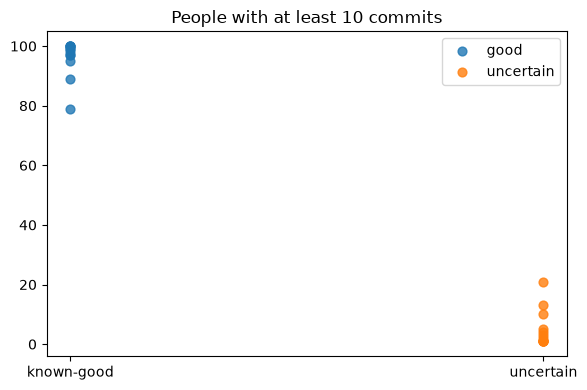

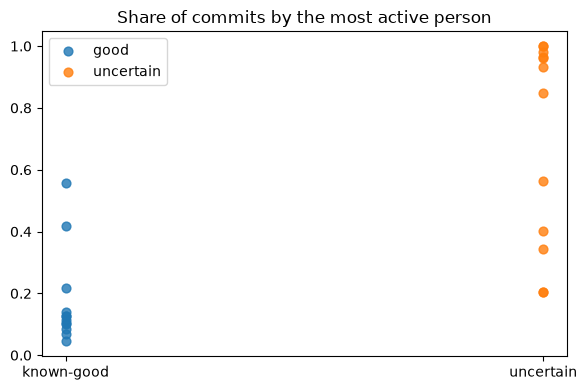

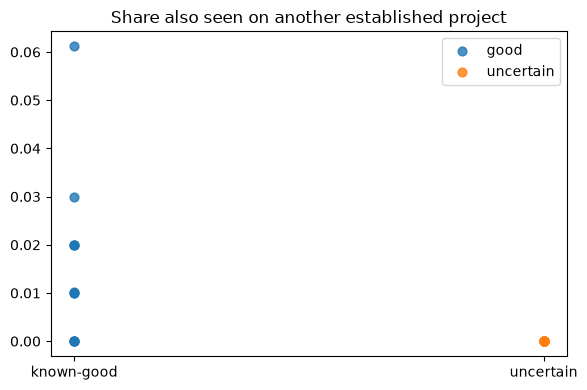

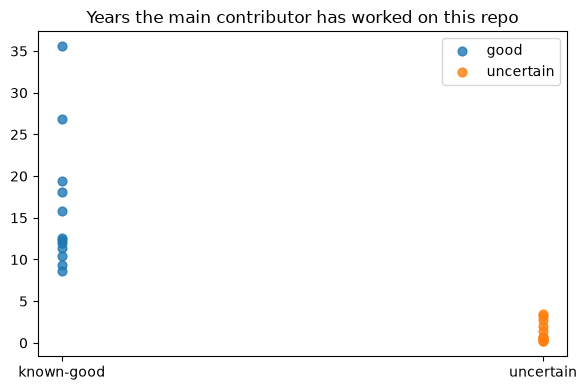

                                repo     label  human_contributor_n  substantive_contributor_n  top_human_share  share_human_contributors_on_other_good_different_owner  primary_human_tenure_days  limited_public_contributor_history
                           curl/curl      good                   98                         79         0.556589                                                0.061224                9799.069086                                   0
                       django/django      good                  100                        100         0.125559                                                0.020000                5776.335093                                   0
                             git/git      good                  100                        100         0.417086                                                0.020000                7083.305903                                   0
                           golang/go      good                  100         

In [3]:
plot_columns = [
    ("substantive_contributor_n", "People with at least 10 commits"),
    ("top_human_share", "Share of commits by the most active person"),
    (
        "share_human_contributors_on_other_good_different_owner",
        "Share also seen on another established project",
    ),
    ("primary_human_tenure_days", "Years the main contributor has worked on this repo"),
]

for column, title in plot_columns:
    fig, axis = plt.subplots(figsize=(6, 4))
    for index, label in enumerate(["good", "uncertain"]):
        values = features.loc[features["label"] == label, column].dropna()
        if column == "primary_human_tenure_days":
            values = values / 365.25
        axis.scatter([index] * len(values), values, s=40, alpha=0.8, label=label)
    axis.set_xticks([0, 1], ["known-good", "uncertain"])
    axis.set_title(title)
    axis.legend()
    fig.tight_layout()
    plt.show()

preview_columns = [
    "repo",
    "label",
    "human_contributor_n",
    "substantive_contributor_n",
    "top_human_share",
    "share_human_contributors_on_other_good_different_owner",
    "primary_human_tenure_days",
    "limited_public_contributor_history",
]
print(features[preview_columns].sort_values(["label", "repo"]).to_string(index=False))


In [4]:
def class_median(column: str, label: str) -> float:
    values = features.loc[features["label"] == label, column].dropna()
    if values.empty:
        return float("nan")
    return float(values.median())


n_good = int((features["label"] == "good").sum())
n_uncertain = int((features["label"] == "uncertain").sum())
good_years = class_median("primary_human_tenure_days", "good") / 365.25
uncertain_years = class_median("primary_human_tenure_days", "uncertain") / 365.25
good_people = class_median("substantive_contributor_n", "good")
uncertain_people = class_median("substantive_contributor_n", "uncertain")
good_share = class_median("top_human_share", "good")
uncertain_share = class_median("top_human_share", "uncertain")
good_overlap = class_median("share_human_contributors_on_other_good_different_owner", "good")
uncertain_overlap = class_median("share_human_contributors_on_other_good_different_owner", "uncertain")
limited_good = int(features.loc[features["label"] == "good", "limited_public_contributor_history"].sum())
limited_uncertain = int(features.loc[features["label"] == "uncertain", "limited_public_contributor_history"].sum())
capped_good = int(features.loc[features["label"] == "good", "contributor_list_capped"].sum())

print(f"This run compared {n_good} known-good repositories with {n_uncertain} uncertain repositories.")
print()
print("1. Do repositories with more experienced contributors tend to be more trustworthy?")
print("We measured experience as how long the main human contributor has been committing to that repository.")
print(f"Known-good median: {good_years:.1f} years. Uncertain median: {uncertain_years:.1f} years.")
print("In this sample, yes. The main contributor on a known-good repository has usually been there much longer.")
print()
print("2. Does having multiple active contributors provide stronger evidence of legitimacy?")
print("An active contributor here means a person with at least 10 commits. Bots are not counted.")
print(f"Known-good median: {good_people:.0f} people. Uncertain median: {uncertain_people:.0f} people.")
print(
    "On a known-good repository the most active person does about "
    f"{good_share:.0%} of the human commits. On an uncertain repository that share is about {uncertain_share:.0%}."
)
print("In this sample, yes. Known-good repositories have more people doing real work, and the work is less concentrated in one account.")
print()
print("3. Can contributors' involvement in established projects help indicate credibility?")
print("We asked whether a repository's people also show up on a known-good repository with a different owner.")
print(f"Known-good median share: {good_overlap:.0%}. Uncertain median share: {uncertain_overlap:.0%}.")
print("The direction says yes, but the gap is small. Most people in this sample were not seen on a second established project.")
print()
print("What to say about the limits:")
print(
    f"{capped_good} of the {n_good} known-good repositories hit GitHub's cap of 100 contributors, "
    "so their counts are 'at least 100,' not an exact total."
)
print("These known-good examples are famous, long-running projects. A small new project will not look like them.")
print(
    f"{limited_uncertain} uncertain repositories and {limited_good} known-good repositories were flagged as having too little public contributor history to judge."
)
print("That flag means 'we cannot tell,' not 'this repository is bad.'")


This run compared 12 known-good repositories with 12 uncertain repositories.

1. Do repositories with more experienced contributors tend to be more trustworthy?
We measured experience as how long the main human contributor has been committing to that repository.
Known-good median: 12.4 years. Uncertain median: 0.7 years.
In this sample, yes. The main contributor on a known-good repository has usually been there much longer.

2. Does having multiple active contributors provide stronger evidence of legitimacy?
An active contributor here means a person with at least 10 commits. Bots are not counted.
Known-good median: 98 people. Uncertain median: 2 people.
On a known-good repository the most active person does about 12% of the human commits. On an uncertain repository that share is about 89%.
In this sample, yes. Known-good repositories have more people doing real work, and the work is less concentrated in one account.

3. Can contributors' involvement in established projects help indicat

## Limits, and what is worth doing next

The rate-limit sample cannot support a stable score by itself. Several good repositories hit the 100-contributor cap, so their headcount is censored. Known-good overlap only sees repositories that were fetched. Commit search can miss history, and it was collected for the primary human only, not for every contributor.

A thin contributor record is missing evidence. The feature table keeps that as `limited_public_contributor_history` so a later model can avoid treating new developers as low trust by default.

With a GitHub token, the next useful measurements are still contributor features, not a separate model:

- Rerun these cells so `study_coverage` becomes `full_labeled_lists`.
- Add account age for the top few human contributors from the user endpoint, and keep missing ages as missing rather than as a penalty.
- Summarize weekly tenure for more than the primary contributor. The stats endpoint can do that, but the raw payload is large, so store the reduced summary rather than the weekly series.
- Add pull-request reviewers. Review history is harder to backdate than commit timestamps, and it is still a contributor signal rather than an organization or star-growth signal.

## Columns in `data/contributor_repo_features.csv`

Join on `repo`. Do not train on `label`, `y_good`, `primary_human_login`, `study_coverage`, or `measured_at`.

- `human_contributor_n`: identifiable people in the returned contributor page.
- `contributor_list_capped`: 1 when the page was full, so the count is censored at 100.
- `substantive_contributor_n`: people with at least 10 default-branch commits.
- `has_multiple_substantive_contributors`: 1 when that count is at least 2.
- `top_human_share`: fraction of human commits by the single most active person.
- `human_contribution_hhi`: Herfindahl index of human commit shares. Higher means more concentrated.
- `human_contributor_effective_n`: inverse of that index.
- `median_human_contributions` and `max_human_contributions`: commit counts among the returned people.
- `bot_contributor_n`: bot accounts in the returned page.
- `share_human_contributors_on_other_good`: leave-one-out share also seen on another fetched known-good repository.
- `human_contributors_on_other_good_n`: count behind that share.
- `other_good_repos_touched_n`: how many other fetched known-good repositories share at least one person.
- `share_human_contributors_on_other_good_different_owner`: the same share after removing repositories with the same owner.
- `primary_human_login`: most active person. An identifier, not a feature.
- `primary_human_contributions`: that person's default-branch commits.
- `primary_human_tenure_days`: days from their earliest indexed commit on this repository to their latest.
- `primary_human_days_since_last_commit`: days from that latest commit to `measured_at`.
- `limited_public_contributor_history`: 1 when the public contributor record is too thin to support a trust judgment.
- `study_coverage`: `full_labeled_lists` or `rate_limit_sample`.
- `measured_at`: when the recency column was computed.